In [2]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", 20)
print("Libraries ready")

Libraries ready


In [3]:
df = pd.read_csv("data/Country-data.csv")
print(df.shape)
df.head()

(167, 10)


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [4]:
df.info()
print("Missing values  :", df.isna().sum().sum())
print("Duplicate names :", df["country"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 14.5 KB
Missing values  : 0
Duplicate names : 0


In [5]:
FEATURES = ["child_mort", "exports", "health", "imports", "income",
            "inflation", "life_expec", "total_fer", "gdpp"]
df[FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
child_mort,167.0,38.27,40.33,2.60,8.25,19.30,62.10,208.00
exports,167.0,41.11,27.41,0.11,23.80,35.00,51.35,200.00
health,167.0,6.82,2.75,1.81,4.92,6.32,8.60,17.90
imports,167.0,46.89,24.21,0.07,30.20,43.30,58.75,174.00
income,167.0,17144.69,19278.07,609.00,3355.00,9960.00,22800.00,125000.00
inflation,167.0,7.78,10.57,-4.21,1.81,5.39,10.75,104.00
life_expec,167.0,70.56,8.89,32.10,65.30,73.10,76.80,82.80
total_fer,167.0,2.95,1.51,1.15,1.80,2.41,3.88,7.49
gdpp,167.0,12964.16,18328.70,231.00,1330.00,4660.00,14050.00,105000.00


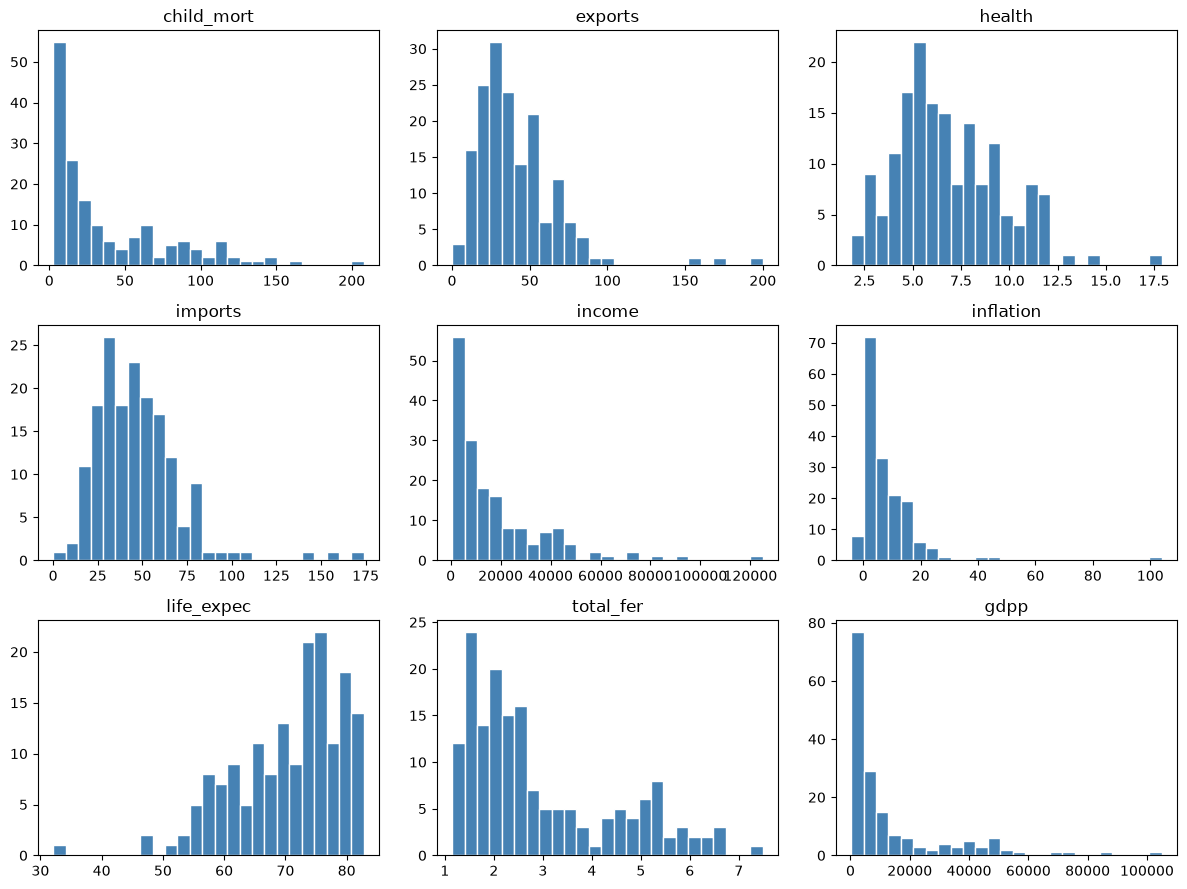

inflation     5.15
exports       2.45
income        2.23
gdpp          2.22
imports       1.91
child_mort    1.45
total_fer     0.97
health        0.71
life_expec   -0.97
dtype: float64


In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.ravel(), FEATURES):
    ax.hist(df[col], bins=25, color="steelblue", edgecolor="white")
    ax.set_title(col)
plt.tight_layout()
plt.show()

print(df[FEATURES].skew().sort_values(ascending=False).round(2))

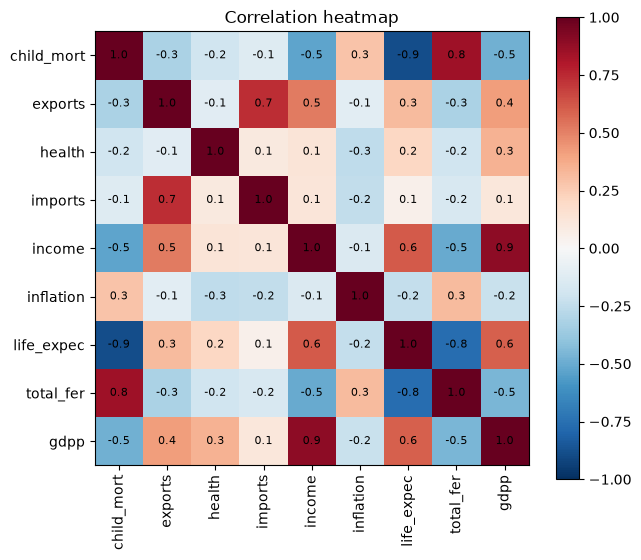

In [7]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=90)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
plt.title("Correlation heatmap")
plt.show()

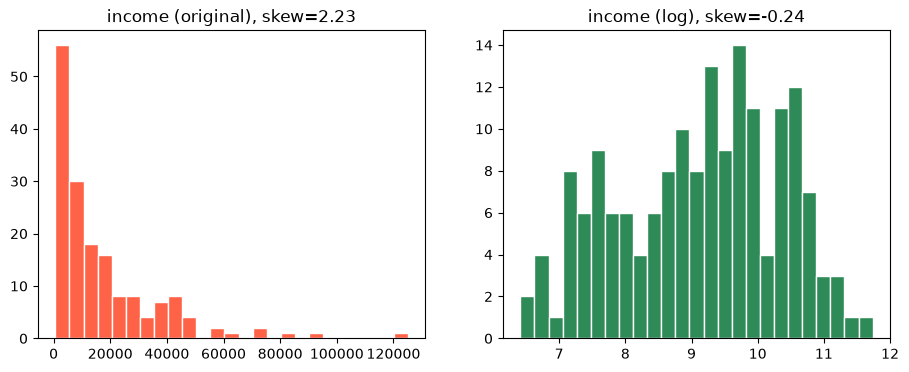

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["income"], bins=25, color="tomato", edgecolor="white")
axes[0].set_title(f"income (original), skew={df['income'].skew():.2f}")

axes[1].hist(np.log1p(df["income"]), bins=25, color="seagreen", edgecolor="white")
axes[1].set_title(f"income (log), skew={np.log1p(df['income']).skew():.2f}")

plt.show()

In [9]:
print(df[["child_mort", "total_fer"]].corr().round(2))

            child_mort  total_fer
child_mort        1.00       0.85
total_fer         0.85       1.00


In [12]:
X = df[FEATURES].astype(float).copy()

# in 4 ke liye log theek raha
for c in ["child_mort", "income", "gdpp"]:
    X[c] = np.log1p(X[c])
X["inflation"] = np.log1p(X["inflation"] - X["inflation"].min())

# exports aur imports: 3 options me se best chuno
for c in ["exports", "imports"]:
    options = {"none": df[c], "sqrt": np.sqrt(df[c]), "log": np.log1p(df[c])}
    skews = {name: round(s.skew(), 2) for name, s in options.items()}
    best = min(options, key=lambda n: abs(options[n].skew()))
    X[c] = options[best]
    print(f"{c}: {skews} -> chosen: {best}")

print()
print(pd.DataFrame({"before": df[FEATURES].skew(), "after": X.skew()}).round(2))

exports: {'none': np.float64(2.45), 'sqrt': np.float64(0.74), 'log': np.float64(-1.09)} -> chosen: sqrt
imports: {'none': np.float64(1.91), 'sqrt': np.float64(0.48), 'log': np.float64(-1.82)} -> chosen: sqrt

            before  after
child_mort    1.45   0.07
exports       2.45   0.74
health        0.71   0.71
imports       1.91   0.48
income        2.23  -0.24
inflation     5.15   0.12
life_expec   -0.97  -0.97
total_fer     0.97   0.97
gdpp          2.22   0.01


In [13]:
scaler = StandardScaler()
Xs = pd.DataFrame(scaler.fit_transform(X), columns=FEATURES, index=df.index)
Xs.describe().T[["mean", "std"]].round(2)

,mean,std
child_mort,-0.0,1.0
exports,0.0,1.0
health,0.0,1.0
imports,-0.0,1.0
income,0.0,1.0
inflation,0.0,1.0
life_expec,0.0,1.0
total_fer,0.0,1.0
gdpp,-0.0,1.0


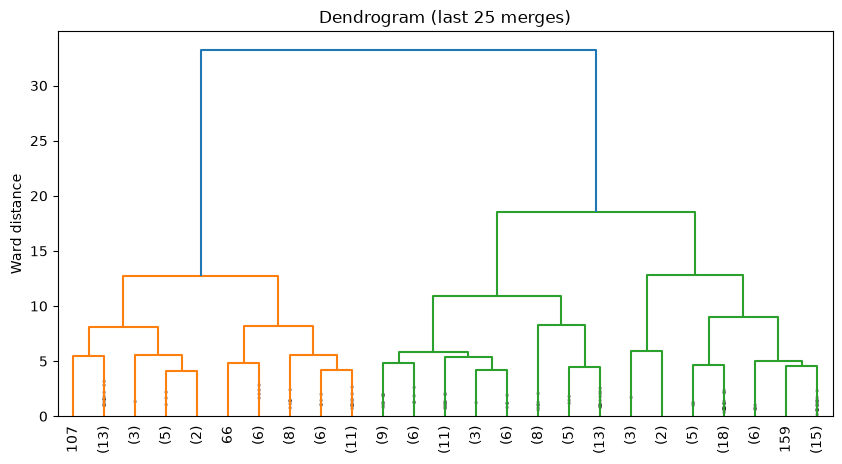

In [14]:
Z = linkage(Xs.values, method="ward")

fig, ax = plt.subplots(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=25, show_contracted=True,
           leaf_rotation=90, ax=ax)
ax.set_ylabel("Ward distance")
ax.set_title("Dendrogram (last 25 merges)")
plt.show()

In [15]:
dist = pdist(Xs.values)
comparison, rows = {}, []

for method in ["ward", "complete", "average", "single"]:
    Zm = linkage(Xs.values, method=method)
    coph, _ = cophenet(Zm, dist)
    sil = {}
    for k in range(2, 9):
        lab = fcluster(Zm, k, "maxclust")
        if len(set(lab)) > 1:
            sil[k] = float(silhouette_score(Xs.values, lab))
    comparison[method] = {"cophenetic": float(coph), "silhouette_by_k": sil}
    rows.append({"method": method,
                 "cophenetic": round(coph, 3),
                 "best_silhouette": round(max(sil.values()), 3),
                 "best_k": max(sil, key=sil.get)})

pd.DataFrame(rows)

,method,cophenetic,best_silhouette,best_k
0,ward,0.593,0.331,2
1,complete,0.551,0.275,2
2,average,0.734,0.375,2
3,single,0.564,0.338,2


In [16]:
for method in ["ward", "average"]:
    Zm = linkage(Xs.values, method=method)
    sizes = pd.Series(fcluster(Zm, 3, "maxclust")).value_counts().sort_index()
    print(method, "->", sizes.to_dict())

ward -> {1: 56, 2: 61, 3: 50}
average -> {1: 5, 2: 161, 3: 1}


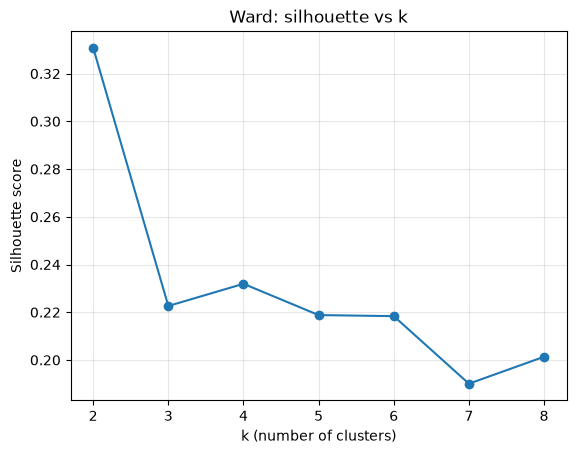

Chosen k: 4


In [17]:
sil_ward = comparison["ward"]["silhouette_by_k"]

plt.plot(list(sil_ward.keys()), list(sil_ward.values()), marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("Silhouette score")
plt.title("Ward: silhouette vs k")
plt.grid(alpha=0.3)
plt.show()

k = max((kk for kk in sil_ward if kk >= 3), key=sil_ward.get)
print("Chosen k:", k)

In [18]:
Zw = linkage(Xs.values, method="ward")

for kk in range(3, 9):
    lab = fcluster(Zw, kk, "maxclust")
    sizes = pd.Series(lab).value_counts().sort_index().tolist()
    print(f"k={kk}  silhouette={sil_ward[kk]:.3f}  sizes={sizes}")
    

k=3  silhouette=0.223  sizes=[56, 61, 50]
k=4  silhouette=0.232  sizes=[56, 61, 5, 45]
k=5  silhouette=0.219  sizes=[24, 32, 61, 5, 45]
k=6  silhouette=0.218  sizes=[24, 32, 35, 26, 5, 45]
k=7  silhouette=0.190  sizes=[24, 32, 35, 26, 5, 23, 22]
k=8  silhouette=0.201  sizes=[24, 32, 35, 8, 18, 5, 23, 22]


In [19]:
lab4 = fcluster(Zw, 4, "maxclust")
small = pd.Series(lab4).value_counts().idxmin()
df.loc[lab4 == small, ["country", "exports", "imports", "income", "child_mort"]]

,country,exports,imports,income,child_mort
73,Ireland,103.0,86.5,45700,4.2
91,Luxembourg,175.0,142.0,91700,2.8
98,Malta,153.0,154.0,28300,6.8
131,Seychelles,93.8,108.0,20400,14.4
133,Singapore,200.0,174.0,72100,2.8


In [20]:
k = 4
Z = linkage(Xs.values, method="ward")
df["cluster_raw"] = fcluster(Z, k, "maxclust")

print(df["cluster_raw"].value_counts().sort_index())
print("Silhouette:", round(silhouette_score(Xs.values, df["cluster_raw"]), 3))

cluster_raw
1    56
2    61
3     5
4    45
Name: count, dtype: int64
Silhouette: 0.232


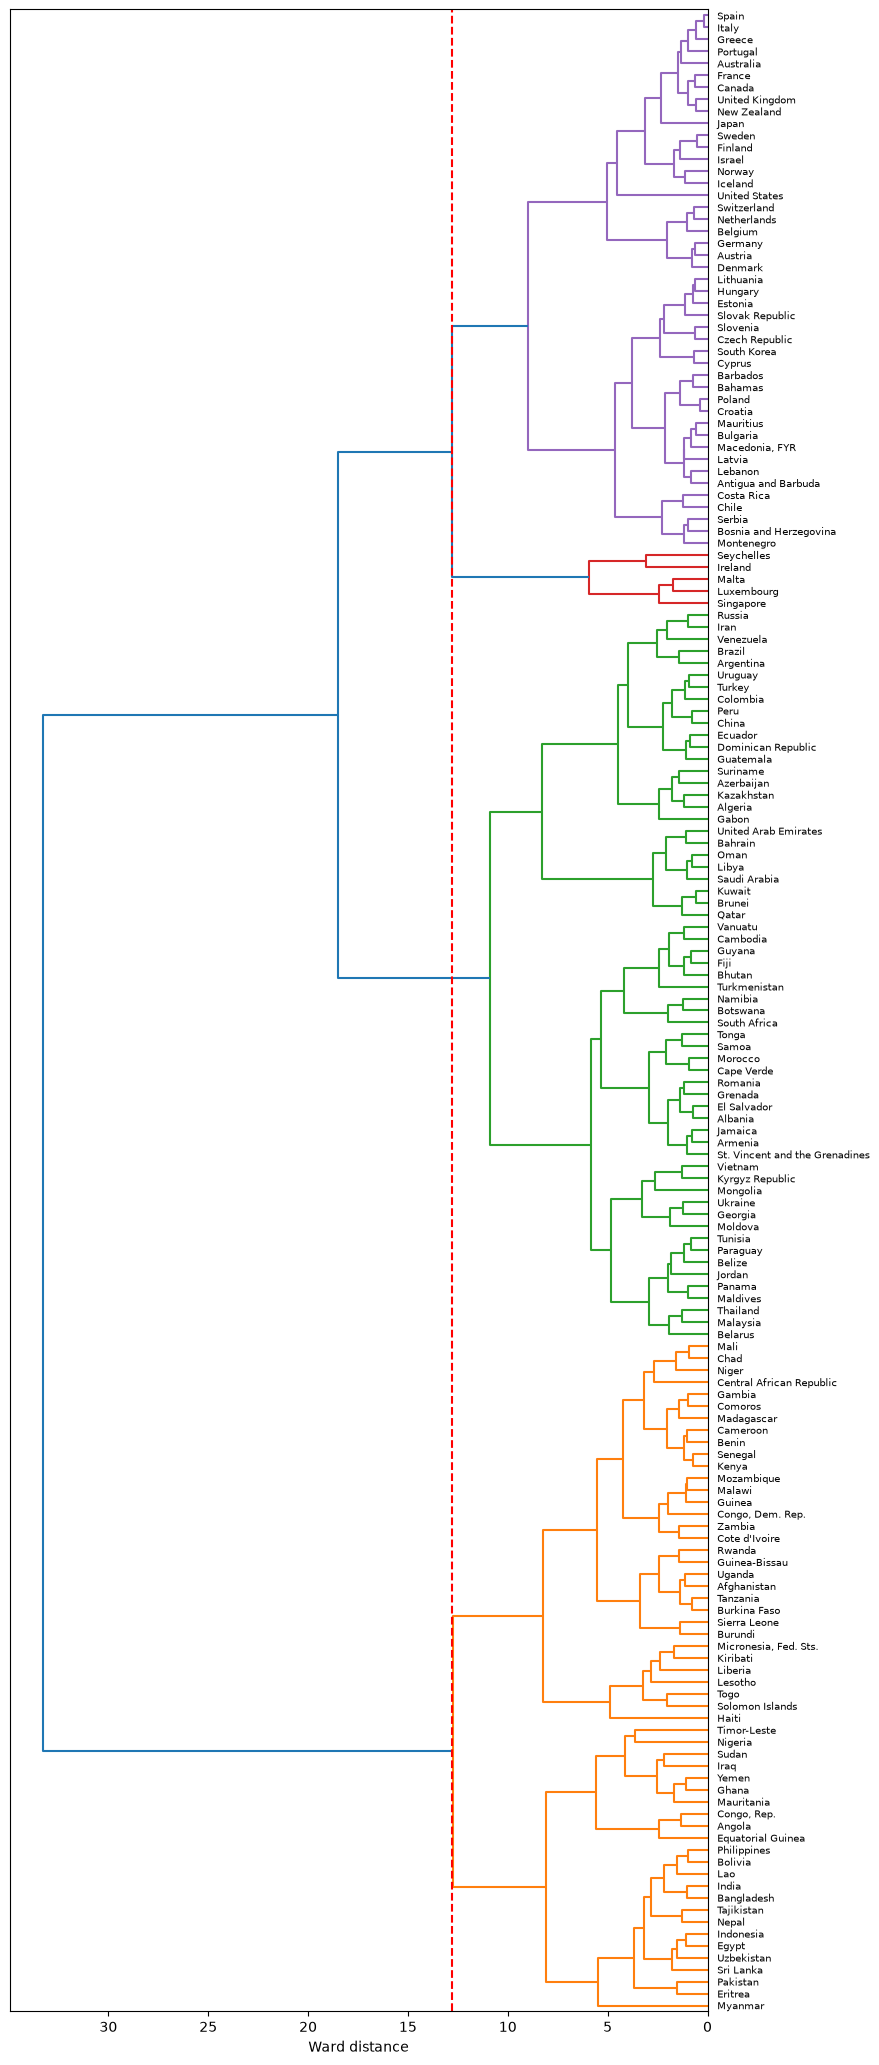

In [21]:
thr = (Z[-k, 2] + Z[-(k - 1), 2]) / 2

fig, ax = plt.subplots(figsize=(9, 26))
dendrogram(Z, labels=df["country"].values, orientation="left",
           color_threshold=thr, leaf_font_size=7, ax=ax)
ax.axvline(thr, color="red", linestyle="--")
ax.set_xlabel("Ward distance")
plt.show()

In [23]:
profile = df.groupby("cluster_raw")[FEATURES].mean().round(2)
profile.insert(0, "countries", df["cluster_raw"].value_counts().sort_index())
profile

,countries,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
cluster_raw,,,,,,,,,,
1,56,83.42,26.81,6.08,41.29,3536.12,11.94,61.46,4.64,1524.43
2,61,23.14,43.90,5.77,45.78,17520.00,9.11,72.22,2.43,8844.36
3,5,6.20,144.96,6.59,132.90,51640.00,-0.01,79.62,1.67,46440.00
4,45,6.15,43.58,9.16,45.80,29738.22,1.68,78.62,1.68,29065.33


In [24]:
NEED_SIGN = {"child_mort": 1, "total_fer": 1, "inflation": 1,
             "income": -1, "gdpp": -1, "life_expec": -1}

df["need_score"] = sum(s * Xs[c] for c, s in NEED_SIGN.items()) / len(NEED_SIGN)

order = df.groupby("cluster_raw")["need_score"].mean().sort_values(ascending=False)
names = {c: f"Group {i + 1}" for i, c in enumerate(order.index)}
df["group"] = df["cluster_raw"].map(names)

print("Average need score per group (Group 1 = highest need):")
print(order.rename(index=names).round(2))
print()
print(pd.Series(names, name="group").rename_axis("cluster_raw"))

Average need score per group (Group 1 = highest need):
cluster_raw
Group 1    0.98
Group 2   -0.11
Group 3   -0.94
Group 4   -1.24
Name: need_score, dtype: float64

cluster_raw
1    Group 1
2    Group 2
4    Group 3
3    Group 4
Name: group, dtype: str


In [25]:
top = df.sort_values("need_score", ascending=False)
top[["country", "group", "need_score", "child_mort", "income", "life_expec"]].head(15).round(2)

,country,group,need_score,child_mort,income,life_expec
37,"Congo, Dem. Rep.",Group 1,1.81,116.0,609,57.5
26,Burundi,Group 1,1.64,93.6,764,57.7
132,Sierra Leone,Group 1,1.60,160.0,1220,55.0
113,Nigeria,Group 1,1.59,130.0,5150,60.5
66,Haiti,Group 1,1.57,208.0,1500,32.1
112,Niger,Group 1,1.51,123.0,814,58.8
94,Malawi,Group 1,1.50,90.5,1030,53.1
106,Mozambique,Group 1,1.46,101.0,918,54.5
31,Central African Republic,Group 1,1.44,149.0,888,47.5
63,Guinea,Group 1,1.44,109.0,1190,58.0


In [26]:
for g, sub in df.groupby("group"):
    print(f"{g} ({len(sub)} countries):")
    print(", ".join(sub.sort_values("need_score", ascending=False)["country"].head(12)), "...")
    print()

Group 1 (56 countries):
Congo, Dem. Rep., Burundi, Sierra Leone, Nigeria, Haiti, Niger, Malawi, Mozambique, Central African Republic, Guinea, Uganda, Chad ...

Group 2 (61 countries):
Mongolia, Kyrgyz Republic, Gabon, Cambodia, Namibia, Botswana, Vanuatu, South Africa, Guyana, Vietnam, Guatemala, Bhutan ...

Group 3 (45 countries):
Serbia, Macedonia, FYR, Costa Rica, Mauritius, Chile, Bulgaria, Bosnia and Herzegovina, Montenegro, Antigua and Barbuda, Barbados, Lithuania, Lebanon ...

Group 4 (5 countries):
Malta, Seychelles, Luxembourg, Singapore, Ireland ...



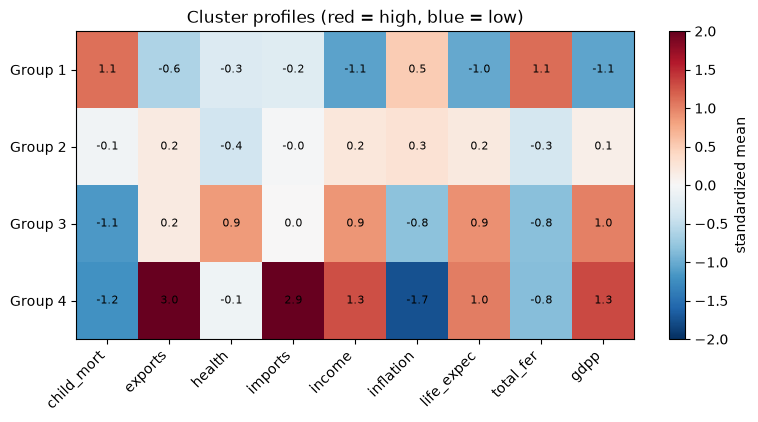

In [27]:
z = Xs.groupby(df["group"]).mean().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(z))); ax.set_yticklabels(z.index)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="standardized mean")
plt.title("Cluster profiles (red = high, blue = low)")
plt.show()

In [28]:
Path("models").mkdir(exist_ok=True)

metrics = {
    "k": int(k),
    "silhouette": float(silhouette_score(Xs.values, df["cluster_raw"])),
    "comparison": comparison,
    "n_countries": int(len(df)),
}

df.to_csv("countries_clustered.csv", index=False)
joblib.dump({"scaler": scaler, "linkage": Z, "X_scaled": Xs, "features": FEATURES},
            "models/artifacts.joblib")
Path("models/metrics.json").write_text(json.dumps(metrics, indent=2))

print("Saved: countries_clustered.csv, models/artifacts.joblib, models/metrics.json")

Saved: countries_clustered.csv, models/artifacts.joblib, models/metrics.json
